# Routing the commutes: first steps with cafein and r5py, London

The commuting flows of 04.1 are counts between grid cells. To turn them into time,
money and emissions we need routes between the cells, by mode. Two routing tools
are available in this environment and this notebook sets both up on the same city
and the same test trips, so that later we can choose, or use both:

| Tool | What it is | Inputs | Gives |
|---|---|---|---|
| **cafein** (`StreetNetwork`, `TransportNetwork`) | The library used in the Helsinki notebooks 02.x | OpenStreetMap extract (`.osm.pbf`); GTFS timetable for transit; optional elevation model | Travel time, and with `TravelCostMatrix` also distance, fares and emissions |
| **r5py** (Tenkanen and Fink, Aalto / Helsinki) | Python wrapper around Conveyal's R5 routing engine (Java) | The same OpenStreetMap extract; GTFS for transit | Travel time matrices, detailed itineraries |

London goes first: it is the best-validated European city in the dataset, and its
grid matches Greater London.

| Step | What we do |
|---|---|
| 1. Inputs | Check which input files exist for London and where they come from |
| 2. Test trips | The ten strongest commuting pairs of London from 04.1, as points to route between |
| 3. Snapping | The street network, and where each cell centre lands on it under the 1 km, inside-the-cell rule |
| 4. Timetables | Buses from the Bus Open Data Service through transitio; rail and TfL from gb-transit; a look inside both |
| 5. Routing | cafein network with both timetables, and the test trips by car, bicycle and transit |
| 6. Whole city | The three modes for every pair of routing points, joined to the commuting flows |
| 7. Per cell | Median commuting time of each cell's residents, by mode: table and map |

The routing steps are added one at a time from here.

In [1]:
import json
import time
import urllib.request
import zipfile
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from shapely.ops import nearest_points

import transitio
from cafein import StreetNetwork, TransportNetwork, TravelTimeMatrix
from cafein._streaming import read_shards

## Parameters

The OpenStreetMap extract is Geofabrik's Greater London file (about 130 MB,
`download.geofabrik.de/europe/united-kingdom/england/greater-london-latest.osm.pbf`,
downloaded 2026-11-02). Routing settings are added when the routing steps are.

In [2]:
CITY = "London"
CITY_ID = "187_GB_London"

DATA = Path("/scratch/project_2010423/data")
OSM_PBF = DATA / "osm" / "greater-london-latest.osm.pbf"
OD_FOLDER = DATA / "worldcommuting-od" / CITY_ID
RESULTS = Path("/scratch/project_2010423/carbon-advantage/commuting") / CITY.lower()
RESULTS.mkdir(parents=True, exist_ok=True)

TEST_PAIRS = 10   # strongest OD pairs used as test trips

# Street network artifact built once from the extract and saved in networks/.
STREET_ARTIFACT = Path("../networks/london-streets.cafein")
COUNTRY = "GB"    # legal default speed limits for ways without a maxspeed tag (car routing)

# Where the routing point of a cell starts before snapping: "geometric" is the centre of
# the square; "population" is the mean of the WorldPop 2020 pixel centres inside the
# cell, weighted by their population, so the point sits where people live.
POINT_METHOD = "population"
WORLDPOP_RASTER = DATA / "worldpop-2020-1km" / "gbr_ppp_2020_1km_Aggregated_UNadj.tif"
MATRICES = RESULTS / POINT_METHOD   # whole-city matrices per point method
MATRICES.mkdir(parents=True, exist_ok=True)

# Snapping rule: a cell centre may be moved to the nearest street up to this far,
# and only to a street inside its own cell.
SNAP_DISTANCE_M = 1000

# Transit timetables (step 4).
GTFS_DIR = DATA / "gtfs" / CITY.lower()
GTFS_DIR.mkdir(parents=True, exist_ok=True)
BODS_FEED_ID = "f-bus~dft~gov~uk"        # Bus Open Data Service aggregate, in transitio's index
GB_TRANSIT_RELEASE = "feed-2026-10-25"   # gb-transit release: National Rail + TfL tube, DLR, trams, river, cable car
GB_TRANSIT_URL = f"https://github.com/planarnetwork/gb-transit/releases/download/{GB_TRANSIT_RELEASE}/gtfs-rail-and-tfl.zip"
GB_TRANSIT_GTFS = GTFS_DIR / f"gb-transit-rail-and-tfl-{GB_TRANSIT_RELEASE}.zip"

# Routing (step 5). As in the Helsinki notebooks: one departure on a normal Tuesday
# morning at 08:30, inside the validity of both feeds (BODS 2026-10-22 to 2027-08-01,
# gb-transit 2026-10-25 to 2027-01-25). Both feeds run a full weekday service on this
# date: 128,448 bus and Underground trips, 34,495 rail and TfL trips.
DEPARTURE = "2026-11-10 08:30"
MODES = ["car", "bicycle", "transit"]
TRANSIT_ARTIFACT = Path("../networks/london-transit.cafein")
RUN_ROUTING = True    # set to False to define the routing functions without building or routing

## 1. Inputs

What London needs and what is already on disk. The transit row is the missing piece.

In [3]:
inputs = pd.DataFrame([
    {"input": "commuting OD grid and matrix", "path": str(OD_FOLDER), "exists": OD_FOLDER.exists(),
     "source": "WorldCommuting-OD repository (04.1)"},
    {"input": "OpenStreetMap extract", "path": str(OSM_PBF), "exists": OSM_PBF.exists(),
     "source": "Geofabrik, Greater London"},
    {"input": "GTFS timetable (transit)", "path": "", "exists": False,
     "source": "to decide: Transport for London data is published through the UK Bus Open Data Service"},
    {"input": "elevation model (slopes for cycling)", "path": "", "exists": False,
     "source": "to decide: optional, Helsinki used a national DEM"},
])
inputs

,input,path,exists,source
0,commuting OD grid and matrix,/scratch/project_2010423/data/worldcommuting-o...,True,WorldCommuting-OD repository (04.1)
1,OpenStreetMap extract,/scratch/project_2010423/data/osm/greater-lond...,True,"Geofabrik, Greater London"
2,GTFS timetable (transit),,False,to decide: Transport for London data is publis...
3,elevation model (slopes for cycling),,False,"to decide: optional, Helsinki used a national DEM"


## 2. Test trips

The London grid and matrix are read as in 04.1. Each cell is represented by its
centre, converted to latitude and longitude, because both tools route between
points. The ten strongest pairs become the test trips. A cell centre can fall in a
park, a reservoir or the Thames; how far a point may be moved to the nearest street
is decided when the routing is set up.

In [4]:
regions = gpd.read_file(OD_FOLDER / "CityAndRegionSplit" / "regions.shp")
flows = np.load(OD_FOLDER / "CommutingODFlows" / "generation.npy").astype(float)
assert len(regions) == flows.shape[0]

# One point per cell, in latitude-longitude, with the grid id as the point id.
centres = regions.copy()
centres["geometry"] = regions.geometry.centroid
centres = centres.to_crs("EPSG:4326")[["locations", "geometry"]].rename(columns={"locations": "id"})

# The strongest pairs of the matrix.
origin, destination = np.nonzero(flows)
pairs = pd.DataFrame({"origin": origin, "destination": destination, "flow": flows[origin, destination]})
pairs = pairs.nlargest(TEST_PAIRS, "flow").reset_index(drop=True)
pairs["from_id"] = centres["id"].to_numpy()[pairs["origin"]]
pairs["to_id"] = centres["id"].to_numpy()[pairs["destination"]]

# Straight-line distance between the two centres, in the metric grid projection.
metric = regions.geometry.centroid
dx = metric.x.to_numpy()[pairs["destination"]] - metric.x.to_numpy()[pairs["origin"]]
dy = metric.y.to_numpy()[pairs["destination"]] - metric.y.to_numpy()[pairs["origin"]]
pairs["straight_km"] = np.hypot(dx, dy) / 1000

print(f"{len(centres)} cell centres; {len(pairs)} test trips")
pairs[["from_id", "to_id", "flow", "straight_km"]].round(2)

281 cell centres; 10 test trips


,from_id,to_id,flow,straight_km
0,14-14,11-10,3320.0,12.31
1,6-3,8-9,2918.0,16.11
2,1-8,8-9,2727.0,18.27
3,14-14,12-10,2687.0,10.95
4,6-3,10-6,2626.0,13.01
5,14-14,10-10,2616.0,14.02
6,14-14,10-11,2473.0,12.35
7,6-3,9-8,2460.0,14.95
8,13-4,12-8,2420.0,10.65
9,13-4,11-9,2340.0,13.92


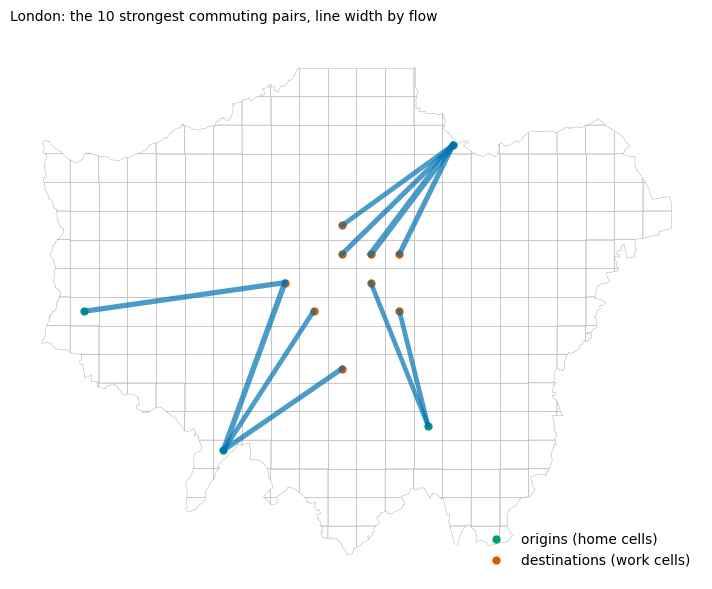

In [5]:
# The points that take part in the test trips, as origins and destinations.
origins = centres.loc[centres["id"].isin(pairs["from_id"])].reset_index(drop=True)
destinations = centres.loc[centres["id"].isin(pairs["to_id"])].reset_index(drop=True)

figure, axis = plt.subplots(figsize=(8, 6))
regions.plot(ax=axis, facecolor="none", edgecolor="#bbbbbb", linewidth=0.4)
for _, trip in pairs.iterrows():
    a = metric.iloc[trip["origin"]]
    b = metric.iloc[trip["destination"]]
    axis.plot([a.x, b.x], [a.y, b.y], color="#0072B2", linewidth=0.5 + 4 * trip["flow"] / pairs["flow"].max(), alpha=0.7)
origins.to_crs(regions.crs).plot(ax=axis, color="#009E73", markersize=25, label="origins (home cells)")
destinations.to_crs(regions.crs).plot(ax=axis, color="#D55E00", markersize=25, label="destinations (work cells)")
axis.legend(frameon=False, loc="lower right")
axis.set_title(f"{CITY}: the {TEST_PAIRS} strongest commuting pairs, line width by flow", loc="left", fontsize=10)
axis.set_axis_off()
figure.tight_layout()

## 3. The street network and the snapping rule

Routing starts and ends on a street, so each cell centre has to be moved to one.
The rule: the nearest street point that is **inside the cell**, and at most
`SNAP_DISTANCE_M` away. If a cell has no street within that distance inside its
own square, it is left without a routable point and we need to decide what to do
with it.

The streets come from the cafein street network of Greater London, built once from
the OSM extract (walk, bicycle and car) and saved in `networks/`. Every edge
of that network counts as a street here, whatever modes may use it.

In [6]:
if STREET_ARTIFACT.exists():
    streets = StreetNetwork.load(STREET_ARTIFACT)
    print("loaded", STREET_ARTIFACT)
else:
    streets = StreetNetwork.from_osm(OSM_PBF, modes=("walk", "bicycle", "car"), country=COUNTRY)
    streets.save(STREET_ARTIFACT)
    print("built and saved", STREET_ARTIFACT)

# The edges as lines, in the metric projection of the grid.
edges = streets.streets_gdf.to_crs(regions.crs)
print(f"vertices {streets.vertex_count:,}, edges {len(edges):,}")

loaded london-streets.cafein


vertices 2,067,386, edges 2,296,703


### Where the point starts: geometric or population-weighted centre

The geometric centre of a 2.6 km square can sit in a park, a dock or a reservoir, far
from where its residents live. With `POINT_METHOD = "population"` the starting point
is instead the population-weighted mean of the WorldPop 2020 pixel centres that fall
inside the cell (1 km pixels here; WorldPop also publishes 100 m rasters for every
country, needed for cities with small cells such as Dakar). A cell with no pixel
centre inside, or with zero population, keeps its geometric centre. The same raster
family exists for every country, so this step repeats unchanged in the other cities.

In [7]:
cells = regions[["locations", "geometry"]].copy()
cells["geometric_centre"] = regions.geometry.centroid

# Pixel centres and populations of the WorldPop raster over the grid's bounding box.
with rasterio.open(WORLDPOP_RASTER) as raster:
    bounds = regions.to_crs(raster.crs).total_bounds
    window = rasterio.windows.from_bounds(*bounds, transform=raster.transform)
    values = raster.read(1, window=window)
    transform = raster.window_transform(window)
    nodata = raster.nodata
rows, cols = np.where(values > 0) if nodata is None else np.where((values > 0) & (values != nodata))
xs, ys = rasterio.transform.xy(transform, rows, cols)
pixels = gpd.GeoDataFrame({"population": values[rows, cols]}, geometry=gpd.points_from_xy(xs, ys), crs=raster.crs).to_crs(regions.crs)

# Each pixel centre is assigned to the cell that contains it; weighted mean per cell.
pixels = gpd.sjoin(pixels, cells[["locations", "geometry"]], how="inner", predicate="within")
pixels["wx"] = pixels.geometry.x * pixels["population"]
pixels["wy"] = pixels.geometry.y * pixels["population"]
weighted = pixels.groupby("locations")[["wx", "wy", "population"]].sum()
weighted["x"] = weighted["wx"] / weighted["population"]
weighted["y"] = weighted["wy"] / weighted["population"]

cells = cells.merge(weighted[["x", "y", "population"]], on="locations", how="left")
has_population = cells["population"] > 0
cells["population_centre"] = cells["geometric_centre"]
cells.loc[has_population, "population_centre"] = gpd.points_from_xy(cells.loc[has_population, "x"], cells.loc[has_population, "y"])
cells["centre"] = cells["population_centre"] if POINT_METHOD == "population" else cells["geometric_centre"]
cells["shift_m"] = gpd.GeoSeries(cells["geometric_centre"]).distance(gpd.GeoSeries(cells["population_centre"]))

print(f"{len(pixels):,} WorldPop pixels inside the grid; {has_population.sum()} of {len(cells)} cells get a population-weighted centre")
print("shift from the geometric centre (m):")
cells["shift_m"].describe(percentiles=[0.5, 0.9]).round(0).to_frame().T

2,956 WorldPop pixels inside the grid; 266 of 281 cells get a population-weighted centre
shift from the geometric centre (m):


,count,mean,std,min,50%,90%,max
shift_m,281.0,312.0,228.0,0.0,258.0,626.0,998.0


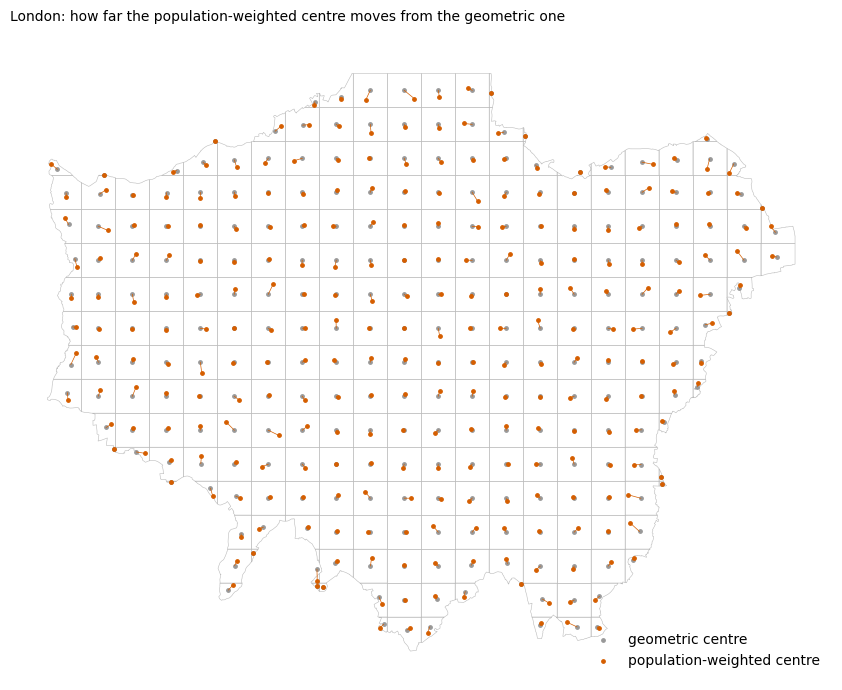

In [8]:
figure, axis = plt.subplots(figsize=(9, 7))
cells.plot(ax=axis, facecolor="none", edgecolor="#bbbbbb", linewidth=0.4)
gpd.GeoSeries(cells["geometric_centre"], crs=regions.crs).plot(ax=axis, color="#999999", markersize=6, label="geometric centre")
gpd.GeoSeries(cells["population_centre"], crs=regions.crs).plot(ax=axis, color="#D55E00", markersize=6, label="population-weighted centre")
for _, cell in cells.iterrows():
    axis.plot([cell["geometric_centre"].x, cell["population_centre"].x], [cell["geometric_centre"].y, cell["population_centre"].y], color="#D55E00", linewidth=0.5)
axis.legend(frameon=False, loc="lower right")
axis.set_title(f"{CITY}: how far the population-weighted centre moves from the geometric one", loc="left", fontsize=10)
axis.set_axis_off()
figure.tight_layout()

Each cell is matched with the edges that cross it. The part of those edges inside
the cell is the set of streets the centre may be moved to, and the closest point of
that set is the snapped point.

In [9]:
# Which edges touch which cell (an edge crossing a border appears in both cells).
edges_in_cells = gpd.sjoin(edges[["geometry"]], cells[["locations", "geometry"]], how="inner", predicate="intersects")

snapped = []
for _, cell in cells.iterrows():
    inside = edges_in_cells.loc[edges_in_cells["locations"] == cell["locations"], "geometry"]
    if len(inside) == 0:
        snapped.append({"locations": cell["locations"], "snap_distance_m": np.nan, "snapped": None})
        continue
    # Keep only the parts of the edges that lie inside the cell, then take the closest point.
    streets_inside = inside.intersection(cell["geometry"]).union_all()
    point_on_street = nearest_points(cell["centre"], streets_inside)[1]
    snapped.append({"locations": cell["locations"],
                    "snap_distance_m": cell["centre"].distance(point_on_street),
                    "snapped": point_on_street})
snapped = pd.DataFrame(snapped)

cells = cells.merge(snapped, on="locations")
cells["within_rule"] = cells["snap_distance_m"] <= SNAP_DISTANCE_M
cells["cell_area_km2"] = cells.geometry.area / 1e6

print(f"{len(cells)} cells; {cells['snap_distance_m'].isna().sum()} with no street inside at all; "
      f"{(~cells['within_rule']).sum()} left without a point under the {SNAP_DISTANCE_M} m rule")
print("distance from centre to the snapped point (m):")
cells["snap_distance_m"].describe(percentiles=[0.5, 0.9, 0.99]).round(0).to_frame().T

281 cells; 2 with no street inside at all; 2 left without a point under the 1000 m rule
distance from centre to the snapped point (m):


,count,mean,std,min,50%,90%,99%,max
snap_distance_m,279.0,28.0,50.0,0.0,15.0,60.0,136.0,697.0


In [10]:
print("Cells left without a routable point:")
cells.loc[~cells["within_rule"], ["locations", "cell_area_km2", "snap_distance_m"]].round(1)

Cells left without a routable point:


,locations,cell_area_km2,snap_distance_m
8,1-5,0.1,NaN
177,13-1,0.0,NaN


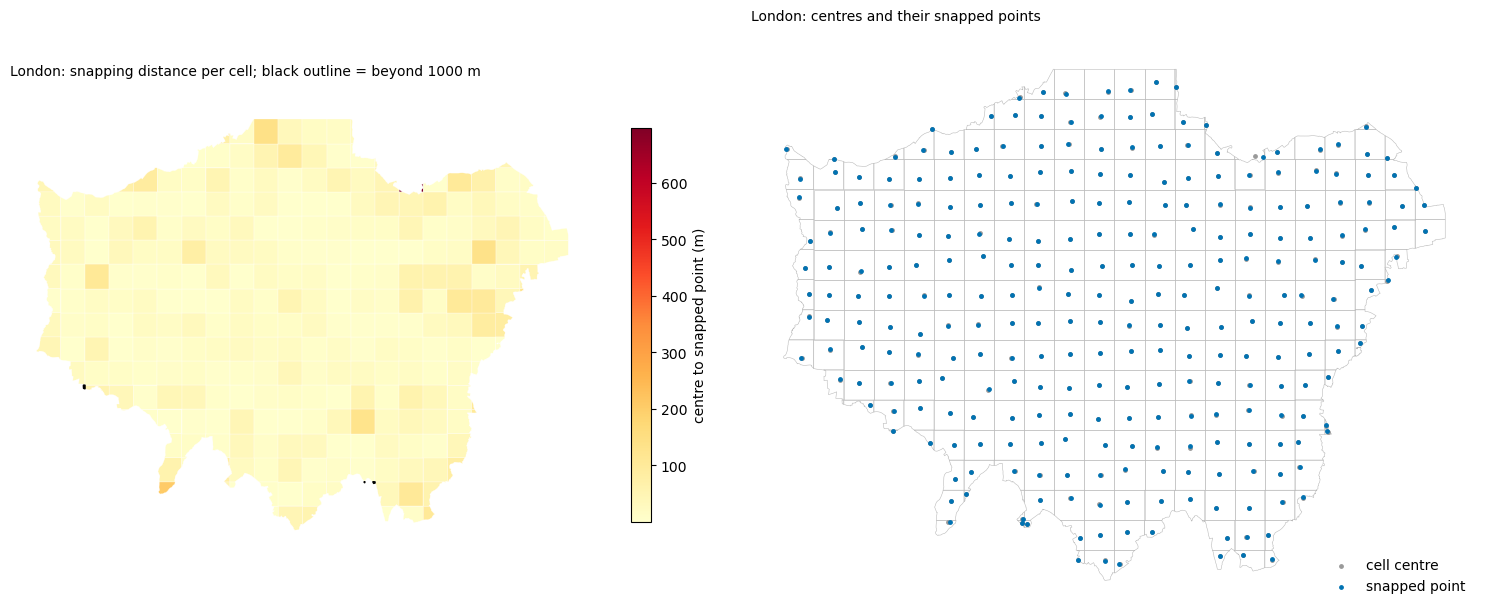

In [11]:
figure, axes = plt.subplots(ncols=2, figsize=(15, 6))

cells.plot(column="snap_distance_m", ax=axes[0], cmap="YlOrRd", edgecolor="white", linewidth=0.2,
           legend=True, legend_kwds={"shrink": 0.7, "label": "centre to snapped point (m)"},
           missing_kwds={"color": "#444444", "label": "no street inside"})
cells.loc[~cells["within_rule"]].plot(ax=axes[0], facecolor="none", edgecolor="black", linewidth=1.2)
axes[0].set_title(f"{CITY}: snapping distance per cell; black outline = beyond {SNAP_DISTANCE_M} m", loc="left", fontsize=10)

ok = cells.loc[cells["within_rule"]]
cells.plot(ax=axes[1], facecolor="none", edgecolor="#bbbbbb", linewidth=0.4)
gpd.GeoSeries(ok["centre"], crs=regions.crs).plot(ax=axes[1], color="#999999", markersize=6, label="cell centre")
gpd.GeoSeries(ok["snapped"], crs=regions.crs).plot(ax=axes[1], color="#0072B2", markersize=6, label="snapped point")
axes[1].legend(frameon=False, loc="lower right")
axes[1].set_title(f"{CITY}: centres and their snapped points", loc="left", fontsize=10)
for axis in axes:
    axis.set_axis_off()
figure.tight_layout()

The snapped points are what the routing uses from now on: one point per cell, with
the grid id as its id, in latitude and longitude as cafein expects. The two cells
without a street are left out for now.

In [12]:
routing_points = gpd.GeoDataFrame(
    {"id": cells.loc[cells["within_rule"], "locations"].to_numpy()},
    geometry=cells.loc[cells["within_rule"], "snapped"].to_numpy(),
    crs=regions.crs,
).to_crs("EPSG:4326")

print(f"{len(routing_points)} routing points")
routing_points.head()

279 routing points


,id,geometry
0,0-7,POINT (-0.48852 51.46703)
1,0-8,POINT (-0.47696 51.49866)
2,0-9,POINT (-0.47649 51.51627)
3,0-10,POINT (-0.48005 51.53654)
4,0-11,POINT (-0.47257 51.55748)


## 4. Transit timetables

London has no single GTFS feed. Two sources are combined:

- **Buses**: the UK Bus Open Data Service aggregate, fetched through transitio, which
  downloads the national file, crops it to the London polygon of its place index,
  validates it and repairs what it can. transitio's recommendation for London also
  lists small fringe operators and a 2021 rail file; only the bus aggregate is taken
  from it, the rail comes from the second source.
- **Rail, Underground, DLR, trams, river and cable car**: the `gtfs-rail-and-tfl.zip`
  file of the gb-transit project (Planar Network), rebuilt nightly from the National
  Rail timetable and TfL's journey planner timetables. The release is pinned in the
  parameters so the run is reproducible. The TfL part of that release is built from a
  copy of TfL's timetables saved on 2026-10-02, because TfL refused the automated
  download afterwards. It is a national file; cropping it to London is a later step.

In [13]:
london = transitio.place("London")
print(london, "| country", london.country_code, "| population", f"{london.population:,}")

started = time.time()
fetched = transitio.fetch(place=london, feeds=[BODS_FEED_ID], when=pd.Timestamp(DEPARTURE).date(),
                          osm=False, directory=GTFS_DIR)
print(f"transitio fetch done in {time.time() - started:.0f} s")
print("feeds delivered:", fetched.feeds)
print("skipped:", fetched.skipped)
for report in fetched.reports:
    print("report:", str(report)[:600])

Place(tp_37767, city, 'London') | country GB | population 10,408,332


Fetching 1 feed for London


[1/1] f-bus~dft~gov~uk: cached copy reused


Done in 1 min 34 s: 1 feed delivered, 0 skipped


transitio fetch done in 94 s
feeds delivered: [PosixPath('/scratch/project_2010423/data/gtfs/london/f-bus~dft~gov~uk.zip')]
skipped: []
report: {'summary': {'validator': {'name': 'transitio', 'version': '0.28.0'}, 'generatedAt': '2026-11-02T14:05:21.145808+00:00', 'counts': {'errors': 1185, 'warnings': 355, 'infos': 4}, 'suppressedNotices': 0, 'countsAreLowerBounds': False, 'serviceWindow': ['20261022', '20270801'], 'rowCounts': {'agency.txt': 54, 'calendar.txt': 533, 'calendar_dates.txt': 38685, 'feed_info.txt': 1, 'frequencies.txt': 81, 'routes.txt': 1134, 'shapes.txt': 59571, 'stop_times.txt': 18624745, 'stops.txt': 24752, 'trips.txt': 505525}, 'readiness': {'distances': {'cafein': '0.10.0', 'predicted': {'crow_fly': 501918, 'shape


In [14]:
if not GB_TRANSIT_GTFS.exists():
    urllib.request.urlretrieve(GB_TRANSIT_URL, GB_TRANSIT_GTFS)
print(GB_TRANSIT_GTFS.name, f"{GB_TRANSIT_GTFS.stat().st_size / 1e6:.0f} MB")

# The GTFS files we will hand to cafein: the cropped bus feed(s) from transitio and the rail+TfL file.
bus_feeds = [Path(str(feed)) for feed in fetched.feeds]
GTFS_FILES = bus_feeds + [GB_TRANSIT_GTFS]
for path in GTFS_FILES:
    print(path, f"{path.stat().st_size / 1e6:.0f} MB")

gb-transit-rail-and-tfl-feed-2026-10-25.zip 37 MB
/scratch/project_2010423/data/gtfs/london/f-bus~dft~gov~uk.zip 263 MB
/scratch/project_2010423/data/gtfs/london/gb-transit-rail-and-tfl-feed-2026-10-25.zip 37 MB


What is inside each feed: agencies, routes by GTFS route type (0 tram, 1 metro, 2
rail, 3 bus, 4 ferry; 200 and above are extended codes), number of stops and the
calendar span. Read straight from the zip files with pandas.

In [15]:
ROUTE_TYPE_NAMES = {0: "tram", 1: "metro", 2: "rail", 3: "bus", 4: "ferry", 5: "cable tram", 6: "aerial", 7: "funicular", 11: "trolleybus", 12: "monorail"}


def gtfs_summary(path):
    # Counts and dates of one GTFS zip, without unpacking it to disk.
    with zipfile.ZipFile(path) as archive:
        names = set(archive.namelist())
        agency = pd.read_csv(archive.open("agency.txt"))
        routes = pd.read_csv(archive.open("routes.txt"))
        stops = pd.read_csv(archive.open("stops.txt"), usecols=["stop_id"])
        trips = pd.read_csv(archive.open("trips.txt"), usecols=["trip_id"])
        dates = []
        if "calendar.txt" in names:
            calendar = pd.read_csv(archive.open("calendar.txt"), dtype=str)
            dates += [calendar["start_date"].min(), calendar["end_date"].max()]
        if "calendar_dates.txt" in names:
            exceptions = pd.read_csv(archive.open("calendar_dates.txt"), dtype=str)
            dates += [exceptions["date"].min(), exceptions["date"].max()]
    by_type = routes["route_type"].map(lambda t: ROUTE_TYPE_NAMES.get(int(t), f"type {t}")).value_counts()
    return {"file": Path(path).name, "agencies": len(agency), "routes": len(routes), "stops": len(stops), "trips": len(trips),
            "first_date": min(dates), "last_date": max(dates), **{f"routes_{k}": v for k, v in by_type.items()}}


pd.DataFrame([gtfs_summary(path) for path in GTFS_FILES]).set_index("file").T

file,f-bus~dft~gov~uk.zip,gb-transit-rail-and-tfl-feed-2026-10-25.zip
agencies,54,47
routes,1134,78
stops,24752,10191
trips,505525,405325
first_date,20261022,20210103
last_date,20270801,20991231
routes_bus,920.0,NaN
routes_type 200,177.0,NaN
routes_metro,26,11
routes_rail,4,38


## 5. Routing

The three modes on the test trips. `RUN_ROUTING` in the parameters switches the
building and routing off, leaving only the definitions.

1. **Network.** cafein builds one `TransportNetwork` from the two GTFS files and the
   OSM extract, with the street modes added so the same network serves car and
   bicycle. The OSM walking graph is cropped to the London grid polygon, since the
   rail feed is national. Saved as `networks/london-transit.cafein`.
2. **Queries.** One `TravelTimeMatrix` per mode between the routing points of the
   test trips. Car and bicycle use the street network alone (`transport_mode`); car
   is free-flow for now, as in the first test. Transit uses the timetable with the
   departure time; cafein's defaults are kept for walking legs and transfers.
3. **Table.** The test trips with the three times side by side.

In [16]:
def build_transit_network():
    # Build once from the two GTFS files and the OSM extract; reload from the artifact afterwards.
    if TRANSIT_ARTIFACT.exists():
        return TransportNetwork.load(TRANSIT_ARTIFACT)
    network = TransportNetwork.from_gtfs(
        GTFS_FILES,
        osm_pbf=OSM_PBF,
        street_modes=("walk", "bicycle", "car"),
        country=COUNTRY,
        bounding_box=regions.to_crs("EPSG:4326").union_all(),
    )
    network.save(TRANSIT_ARTIFACT)
    return network


def route_test_trips(network, streets, points, trips):
    # Travel times of the test trips for every mode in MODES, in minutes, as one table.
    origins = points.loc[points["id"].isin(trips["from_id"])]
    destinations = points.loc[points["id"].isin(trips["to_id"])]
    table = trips[["from_id", "to_id", "flow", "straight_km"]].copy()
    for mode in MODES:
        if mode == "transit":
            matrix = TravelTimeMatrix(network, origins, destinations, departure=DEPARTURE, output_time_units="seconds")
        else:
            matrix = TravelTimeMatrix(streets, origins, destinations, transport_mode=mode, output_time_units="seconds")
        matrix = matrix.rename(columns={"travel_time": f"{mode}_min"})
        matrix[f"{mode}_min"] = matrix[f"{mode}_min"] / 60
        table = table.merge(matrix[["from_id", "to_id", f"{mode}_min"]], on=["from_id", "to_id"], how="left")
    return table


print("routing functions defined; RUN_ROUTING =", RUN_ROUTING)

routing functions defined; RUN_ROUTING = True


In [17]:
if RUN_ROUTING:
    started = time.time()
    transit_network = build_transit_network()
    print(f"transit network ready in {time.time() - started:.0f} s: {transit_network.stop_count:,} stops, {transit_network.trip_count:,} trips")
    times = route_test_trips(transit_network, streets, routing_points, pairs)
    times.to_parquet(MATRICES / "test_trips_times.parquet", index=False)
    display(times.round(1))
else:
    print("skipped: set RUN_ROUTING = True in the parameters to build the network and route the test trips")

loading the network:   0%|          | 0/2 [00:02<?, ?it/s]

transit network ready in 9 s: 34,943 stops, 911,209 trips


,from_id,to_id,flow,straight_km,car_min,bicycle_min,transit_min
0,14-14,11-10,3320.0,12.3,20.2,55.4,50.9
1,6-3,8-9,2918.0,16.1,28.3,81.9,87.8
2,1-8,8-9,2727.0,18.3,27.9,NaN,69.4
3,14-14,12-10,2687.0,10.9,17.7,53.2,45.8
4,6-3,10-6,2626.0,13.0,24.2,65.4,74.0
5,14-14,10-10,2616.0,14.0,26.0,61.7,62.4
6,14-14,10-11,2473.0,12.3,23.6,58.0,58.8
7,6-3,9-8,2460.0,14.9,23.4,76.6,83.7
8,13-4,12-8,2420.0,10.7,20.3,53.7,96.6
9,13-4,11-9,2340.0,13.9,24.4,62.7,73.3


In [18]:
if RUN_ROUTING:
    # Flow-weighted mean over the test trips, and the straight-line distance covered per hour.
    summary = {}
    for mode in MODES:
        reached = times[f"{mode}_min"].notna()
        minutes = times.loc[reached, f"{mode}_min"]
        summary[mode] = {
            "trips_reached": int(reached.sum()),
            "mean_min_flow_weighted": np.average(minutes, weights=times.loc[reached, "flow"]),
            "straight_line_kmh": times.loc[reached, "straight_km"].sum() / (minutes.sum() / 60),
        }
    display(pd.DataFrame(summary).round(1))

,car,bicycle,transit
trips_reached,10.0,9.0,10.0
mean_min_flow_weighted,23.6,63.2,69.7
straight_line_kmh,34.7,12.5,11.7


## 6. Whole city

The same three queries for every pair of the 279 routing points. Each matrix is
streamed to a folder on scratch (`MATRICES/<mode>/`, one folder per point method) and reused on later runs when
complete. Times in seconds, converted to minutes when read back.

In [19]:
def matrix_complete(path):
    # True when a streamed matrix folder has every shard completed.
    manifest = Path(path) / "manifest.json"
    if not manifest.is_file():
        return False
    shards = json.loads(manifest.read_text())["shards"]
    return bool(shards) and all(shard["completed"] for shard in shards)


QUERIES = {
    "car": dict(network=streets, transport_mode="car"),
    "bicycle": dict(network=streets, transport_mode="bicycle"),
    "transit": dict(network=transit_network, departure=DEPARTURE),
}

for mode in MODES:
    output = MATRICES / mode
    if matrix_complete(output):
        print(f"{mode:8} complete -> {output}")
        continue
    query = dict(QUERIES[mode])
    network = query.pop("network")
    started = time.time()
    TravelTimeMatrix.to_parquet(network, routing_points, routing_points, output=output,
                                output_time_units="seconds", resume=output.exists(), **query)
    print(f"{mode:8} {time.time() - started:6.0f} s -> {output}")

car      complete -> /scratch/project_2010423/carbon-advantage/commuting/london/population/car
bicycle  complete -> /scratch/project_2010423/carbon-advantage/commuting/london/population/bicycle
transit  complete -> /scratch/project_2010423/carbon-advantage/commuting/london/population/transit


The commuting matrix as a long table (one row per pair with a flow), joined to the
three times. The two cells without a routing point drop out here.

In [20]:
ids = regions["locations"].to_numpy()
origin, destination = np.nonzero(flows)
od = pd.DataFrame({"from_id": ids[origin], "to_id": ids[destination], "flow": flows[origin, destination]})
od = od.loc[od["from_id"].isin(routing_points["id"]) & od["to_id"].isin(routing_points["id"])]

for mode in MODES:
    matrix = read_shards(MATRICES / mode)[["from_id", "to_id", "travel_time"]]
    matrix = matrix.rename(columns={"travel_time": f"{mode}_min"})
    matrix[f"{mode}_min"] = matrix[f"{mode}_min"] / 60
    od = od.merge(matrix, on=["from_id", "to_id"], how="left")
od.to_parquet(MATRICES / "od_times.parquet", index=False)

print(f"{len(od):,} OD pairs with a flow, {od['flow'].sum():,.0f} commuters")
od.head()

73,162 OD pairs with a flow, 8,324,159 commuters


,from_id,to_id,flow,car_min,bicycle_min,transit_min
0,0-7,0-8,2.0,11.800000,20.566667,41.466667
1,0-7,0-9,1.0,12.433333,29.600000,41.716667
2,0-7,0-10,1.0,14.650000,39.400000,53.366667
3,0-7,0-12,1.0,21.033333,65.133333,82.016667
4,0-7,0-14,2.0,30.250000,85.716667,91.783333


In [21]:
def weighted_median(values, weights):
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order]) / weights.sum()
    return values[order][np.searchsorted(cumulative, 0.5)]


summary = {}
for mode in MODES:
    reached = od[f"{mode}_min"].notna()
    minutes = od.loc[reached, f"{mode}_min"].to_numpy()
    weights = od.loc[reached, "flow"].to_numpy()
    summary[mode] = {
        "share_of_commuters_reached": weights.sum() / od["flow"].sum(),
        "mean_min_flow_weighted": np.average(minutes, weights=weights),
        "median_min_flow_weighted": weighted_median(minutes, weights),
    }
pd.DataFrame(summary).round(2)

,car,bicycle,transit
share_of_commuters_reached,0.98,0.86,0.99
mean_min_flow_weighted,27.55,69.31,75.30
median_min_flow_weighted,26.90,69.98,74.43


## 7. Median commuting time per home cell

For each home cell, the flow-weighted median of the travel time of its residents'
commutes, per mode. Pairs the mode does not reach are left out of that mode's median.

In [22]:
def median_by_cell(frame, column):
    # Flow-weighted median of one time column, per home cell.
    out = {}
    for cell_id, rows in frame.loc[frame[column].notna()].groupby("from_id"):
        out[cell_id] = weighted_median(rows[column].to_numpy(), rows["flow"].to_numpy())
    return pd.Series(out, name=column)


per_cell = pd.DataFrame({"residents": od.groupby("from_id")["flow"].sum()})
for mode in MODES:
    per_cell[f"{mode}_median_min"] = median_by_cell(od, f"{mode}_min")
per_cell = per_cell.rename_axis("locations").reset_index()
per_cell.to_csv(MATRICES / "median_minutes_by_home_cell.csv", index=False)

print("Across cells:")
display(per_cell[[f"{mode}_median_min" for mode in MODES]].describe(percentiles=[0.25, 0.5, 0.75]).round(1).T)
print("Cells with most residents:")
per_cell.sort_values("residents", ascending=False).head(10).round(1)

Across cells:


,count,mean,std,min,25%,50%,75%,max
car_median_min,276.0,27.9,4.2,20.0,25.1,26.9,29.8,42.9
bicycle_median_min,274.0,73.6,10.8,53.7,65.5,71.1,80.2,101.8
transit_median_min,278.0,78.0,12.5,57.2,70.1,75.0,83.7,141.6


Cells with most residents:


,locations,residents,car_median_min,bicycle_median_min,transit_median_min
223,6-3,87985.0,28.6,76.6,89.5
76,13-4,86992.0,28.0,68.8,87.6
88,14-14,84887.0,23.6,58.6,62.4
241,7-5,59703.0,26.7,59.7,62.5
15,1-8,58545.0,32.4,NaN,86.3
33,10-9,56242.0,35.5,94.0,74.1
236,7-15,55923.0,25.6,73.7,84.8
92,14-4,54790.0,26.0,67.9,82.1
140,17-9,54254.0,33.1,78.5,78.5
60,12-3,53539.0,29.6,70.2,71.0


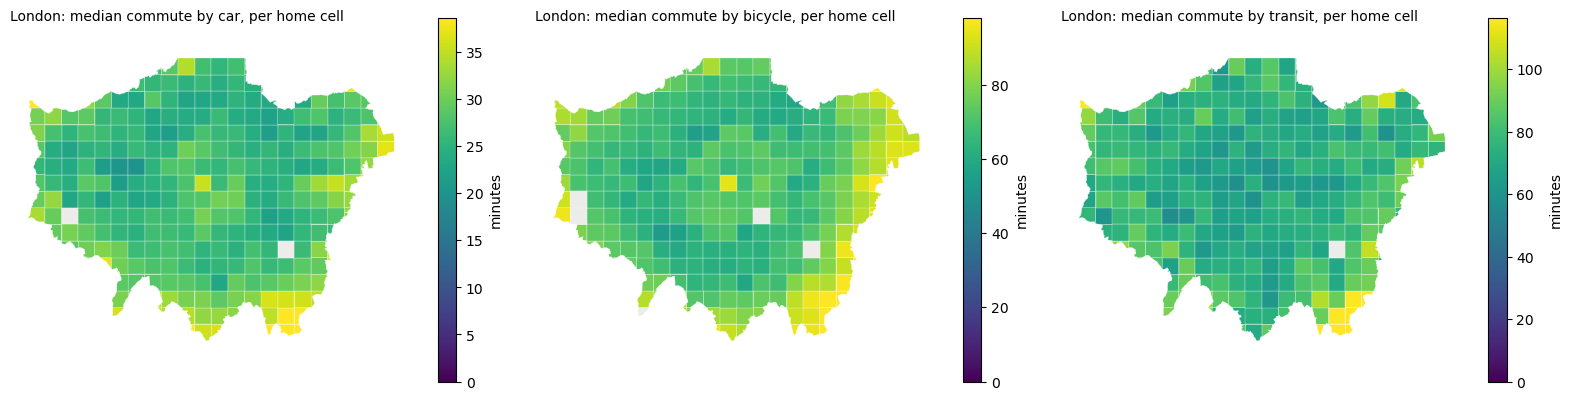

In [23]:
mapped = regions[["locations", "geometry"]].merge(per_cell, on="locations", how="left")
figure, axes = plt.subplots(ncols=3, figsize=(16, 5.5))
for axis, mode in zip(axes, MODES):
    column = f"{mode}_median_min"
    mapped.plot(column=column, ax=axis, cmap="viridis", vmin=0, vmax=np.nanpercentile(mapped[column], 98),
                edgecolor="white", linewidth=0.2, legend=True, legend_kwds={"shrink": 0.7, "label": "minutes"},
                missing_kwds={"color": "#ececea"})
    axis.set_title(f"{CITY}: median commute by {mode}, per home cell", loc="left", fontsize=10)
    axis.set_axis_off()
figure.tight_layout()